## Step 2c: Why did 10 patients score zero?

Ten patients got a Dice score of exactly 0, meaning the model drew nothing for them. This notebook checks a few possible reasons, without any retraining:

1. **Missing scans.** Some patients are missing a scan type, and the gap was filled with a copy of the FLAIR scan.
2. **Brightness.** Images from some hospitals or batches may be brighter or darker overall.
3. **Tumor size and contrast.** Small or faint tumors are harder to spot.
4. **Where the scans came from.** The middle part of each ID (like `HT` or `DU`) is the hospital code.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["font.size"] = 20
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#d9d9d9"
plt.rcParams["axes.axisbelow"] = True

outputs_dir = "project3_outputs_v2"
data_dir = os.path.join("archive", "lgg-mri-segmentation", "kaggle_3m")

failed_color = "#c44536"
ok_color = "#1d3a8a"

print("Done")

Done


In [2]:
scores = pd.read_csv(os.path.join(outputs_dir, "test_dice_scores.csv"))
slices = pd.read_csv(os.path.join(outputs_dir, "slices_with_genetics2.csv"))

scores["Failed"] = scores["Dice"] == 0
print("Patients:", len(scores))
print("Failed (Dice = 0):", scores["Failed"].sum())
print()
print(scores[scores["Failed"]][["Patient", "Fold"]].to_string(index=False))

Patients: 110
Failed (Dice = 0): 2

     Patient  Fold
TCGA_FG_8189     0
TCGA_DU_6405     1


### Measures each patient
For every patient, this goes through all their slices and records:

- **Predicted pixels**, how much tumor the model drew in total. Zero confirms it drew nothing.
- **Tumor pixels**, how much tumor the expert drew in total.
- **Pre-contrast missing / post-contrast missing**, whether that channel is just a copy of the FLAIR channel.
- **Brain brightness**, the average FLAIR brightness inside the brain.
- **Tumor contrast**, how much brighter the tumor is than the rest of the brain on FLAIR. A value of 1.5 means the tumor is 50% brighter.



In [3]:
def local_paths(row):
    image_name = os.path.basename(row["image_file"])
    image_path = os.path.join(data_dir, row["Folder"], image_name)
    mask_path = image_path.replace(".tif", "_mask.tif")
    pred_path = os.path.join(outputs_dir, "predictions", row["Folder"], image_name.replace(".tif", "_pred.png"))
    return image_path, mask_path, pred_path


rows = []
for patient, patient_slices in slices.groupby("Patient"):
    predicted = 0
    tumor = 0
    pre_same = 0
    post_same = 0
    brain_values = []
    tumor_values = []
    healthy_values = []

    for _, row in patient_slices.iterrows():
        image_path, mask_path, pred_path = local_paths(row)
        image = np.array(Image.open(image_path)).astype(float)
        mask = np.array(Image.open(mask_path)) > 0
        prediction = np.array(Image.open(pred_path)) > 0

        pre, flair, post = image[:, :, 0], image[:, :, 1], image[:, :, 2]
        brain = flair > 0

        predicted += prediction.sum()
        tumor += mask.sum()
        pre_same += np.array_equal(pre, flair)
        post_same += np.array_equal(post, flair)

        if brain.any():
            brain_values.append(flair[brain].mean())
        if mask.any():
            tumor_values.append(flair[mask].mean())
            healthy = brain & ~mask
            if healthy.any():
                healthy_values.append(flair[healthy].mean())

    num_slices = len(patient_slices)
    rows.append({
        "Patient": patient,
        "Hospital": patient.split("_")[1],
        "Slices": num_slices,
        "Predicted pixels": int(predicted),
        "Tumor pixels": int(tumor),
        "Pre-contrast missing": pre_same > num_slices / 2,
        "Post-contrast missing": post_same > num_slices / 2,
        "Brain brightness": np.mean(brain_values) if brain_values else np.nan,
        "Tumor contrast": np.mean(tumor_values) / np.mean(healthy_values) if tumor_values and healthy_values else np.nan,
    })

checks = pd.DataFrame(rows).merge(scores, on="Patient")
checks["Any scan missing"] = checks["Pre-contrast missing"] | checks["Post-contrast missing"]
checks.to_csv("failure_checks.csv", index=False)
print("Saved failure_checks.csv")

Saved failure_checks.csv


### Check 1: Did the model draw nothing at all?

In [4]:
failed = checks[checks["Failed"]]
ok = checks[~checks["Failed"]]

print("Failed patients where the model drew nothing:", (failed["Predicted pixels"] == 0).sum(), "of", len(failed))
print()
print(failed[["Patient", "Hospital", "Predicted pixels", "Tumor pixels"]].to_string(index=False))

Failed patients where the model drew nothing: 0 of 2

     Patient Hospital  Predicted pixels  Tumor pixels
TCGA_DU_6405       DU              1403          4822
TCGA_FG_8189       FG             12178         46439


### Check 2: Missing scans
If missing scans are the cause, the failed group should have a much higher share of patients with a missing scan.

In [5]:
for label, group in [("Failed", failed), ("Others", ok)]:
    print(f"{label} ({len(group)} patients)")
    print("   Pre-contrast missing: ", group["Pre-contrast missing"].sum())
    print("   Post-contrast missing:", group["Post-contrast missing"].sum())
    print("   Any scan missing:     ", group["Any scan missing"].sum(),
          f"({100 * group['Any scan missing'].mean():.0f}%)")
    print()

missing = checks[checks["Any scan missing"]]
print("Patients with a missing scan and their Dice:")
print(missing[["Patient", "Pre-contrast missing", "Post-contrast missing", "Dice"]].to_string(index=False))

Failed (2 patients)
   Pre-contrast missing:  0
   Post-contrast missing: 0
   Any scan missing:      0 (0%)

Others (108 patients)
   Pre-contrast missing:  6
   Post-contrast missing: 10
   Any scan missing:      10 (9%)

Patients with a missing scan and their Dice:
     Patient  Pre-contrast missing  Post-contrast missing     Dice
TCGA_DU_6407                 False                   True 0.924626
TCGA_DU_7013                  True                   True 0.369059
TCGA_DU_7301                 False                   True 0.936366
TCGA_DU_8165                 False                   True 0.642949
TCGA_FG_7634                 False                   True 0.829919
TCGA_FG_A60K                  True                   True 0.100882
TCGA_HT_7877                  True                   True 0.833952
TCGA_HT_8105                  True                   True 0.773644
TCGA_HT_A616                  True                   True 0.792179
TCGA_HT_A61B                  True                   True 0.8

### Check 3: Hospital
This shows how many patients from each hospital failed. If one hospital stands out, its scans may look different from the rest.

In [6]:
by_hospital = checks.groupby("Hospital").agg(Patients=("Patient", "count"),
                                              Failed=("Failed", "sum"),
                                              Mean_Dice=("Dice", "mean"))
by_hospital["Mean_Dice"] = by_hospital["Mean_Dice"].round(3)
by_hospital = by_hospital.rename(columns={"Mean_Dice": "Mean Dice"})
print(by_hospital.to_string())

print()
print("Patients with an 'A' in their ID number:")
a_batch = checks["Patient"].str.split("_").str[2].str.startswith("A")
print("   Failed:", (a_batch & checks["Failed"]).sum(), "of", a_batch.sum())

          Patients  Failed  Mean Dice
Hospital                             
CS              16       0      0.604
DU              45       1      0.749
EZ               1       0      0.911
FG              14       1      0.701
HT              34       0      0.831

Patients with an 'A' in their ID number:
   Failed: 0 of 14


### Check 4: Brightness, tumor size, and contrast
Each panel compares the failed patients (red) with everyone else (blue). Each dot is one patient. If the red dots sit apart from the blue ones, that measure is probably part of the problem.

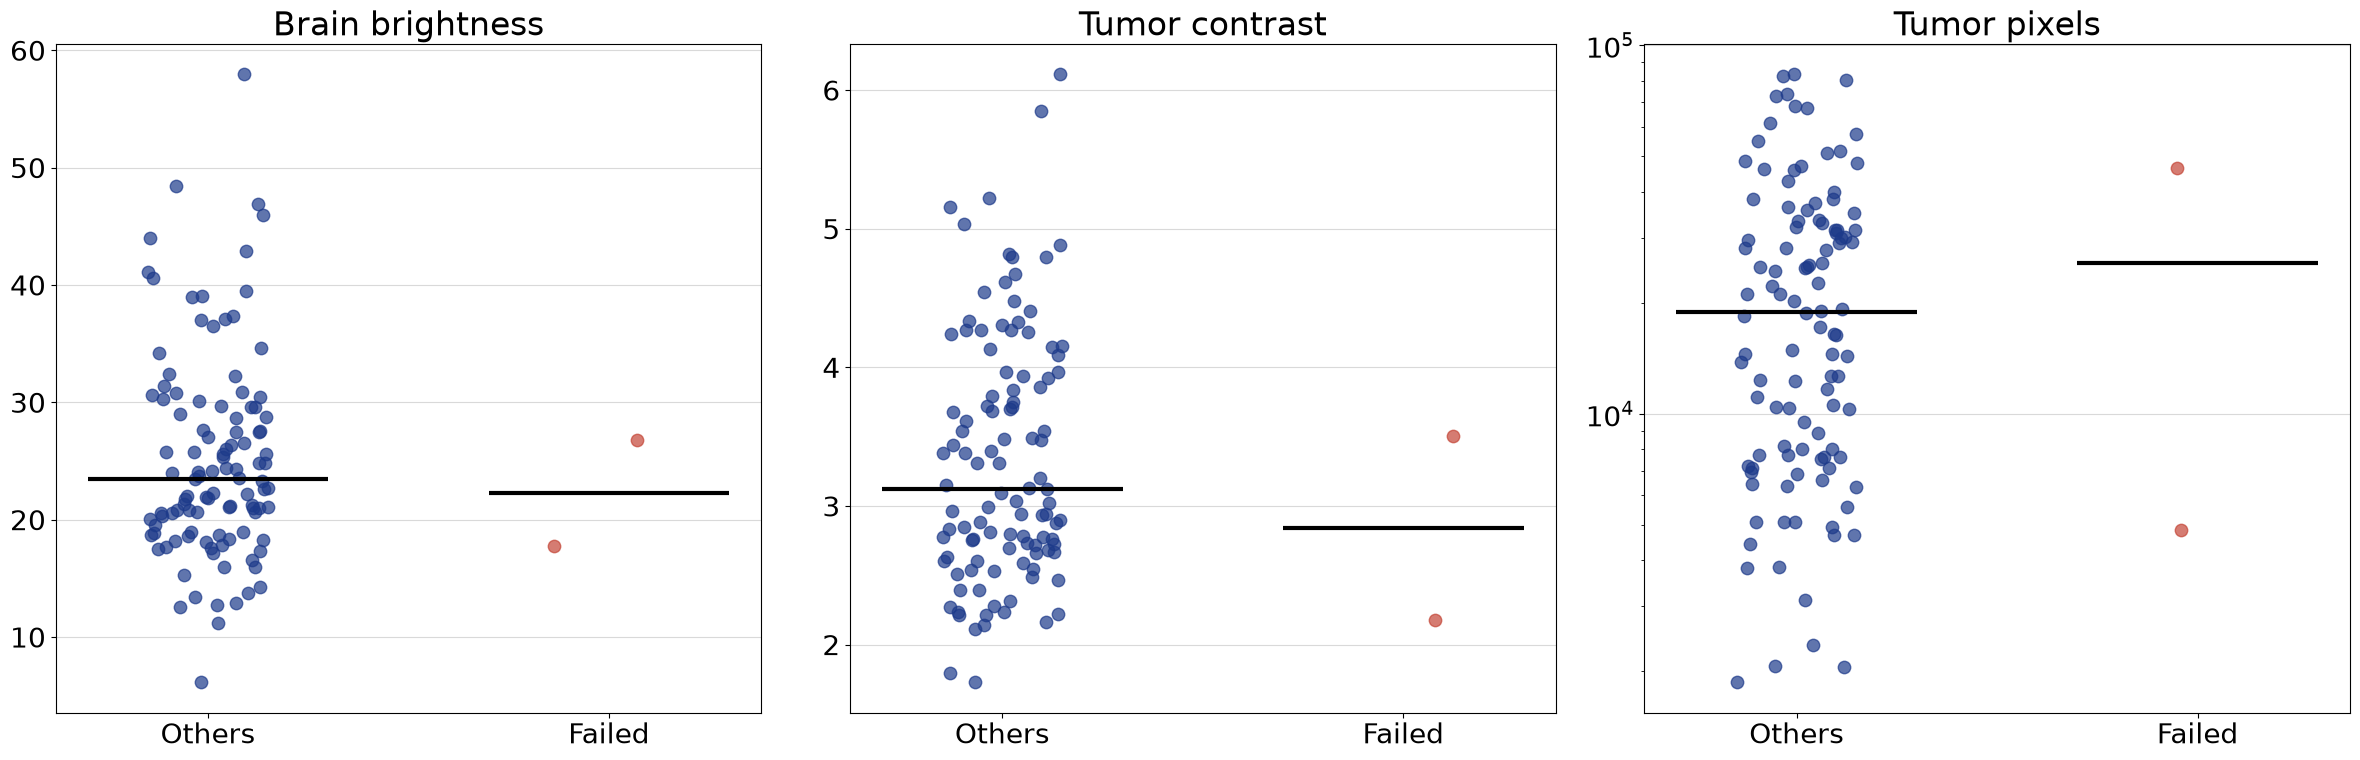

Black lines show the median of each group.

Brain brightness:  Failed median 22.29   Others median 23.50
Tumor contrast:  Failed median 2.84   Others median 3.13
Tumor pixels:  Failed median 25630.50   Others median 18861.00


In [7]:
measures = ["Brain brightness", "Tumor contrast", "Tumor pixels"]

fig, axes = plt.subplots(1, 3, figsize=(24, 8))
rng = np.random.default_rng(0)

for ax, measure in zip(axes, measures):
    for x, (label, group, color) in enumerate([("Others", ok, ok_color), ("Failed", failed, failed_color)]):
        values = group[measure].dropna()
        jitter = rng.uniform(-0.15, 0.15, len(values))
        ax.scatter(np.full(len(values), x) + jitter, values, color=color, s=80, alpha=0.7)
        ax.hlines(values.median(), x - 0.3, x + 0.3, color="black", linewidth=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Others", "Failed"])
    ax.set_title(measure)
    ax.grid(axis="x", visible=False)

axes[2].set_yscale("log")
plt.tight_layout()
plt.savefig("failure_checks.png", dpi=150)
plt.show()

print("Black lines show the median of each group.")
print()
for measure in measures:
    print(f"{measure}:  Failed median {failed[measure].median():.2f}   Others median {ok[measure].median():.2f}")

### Look at the failed patients
For each failed patient, this shows the slice with the most tumor, with the expert's outline in red. Looking at them side by side often makes the pattern obvious.

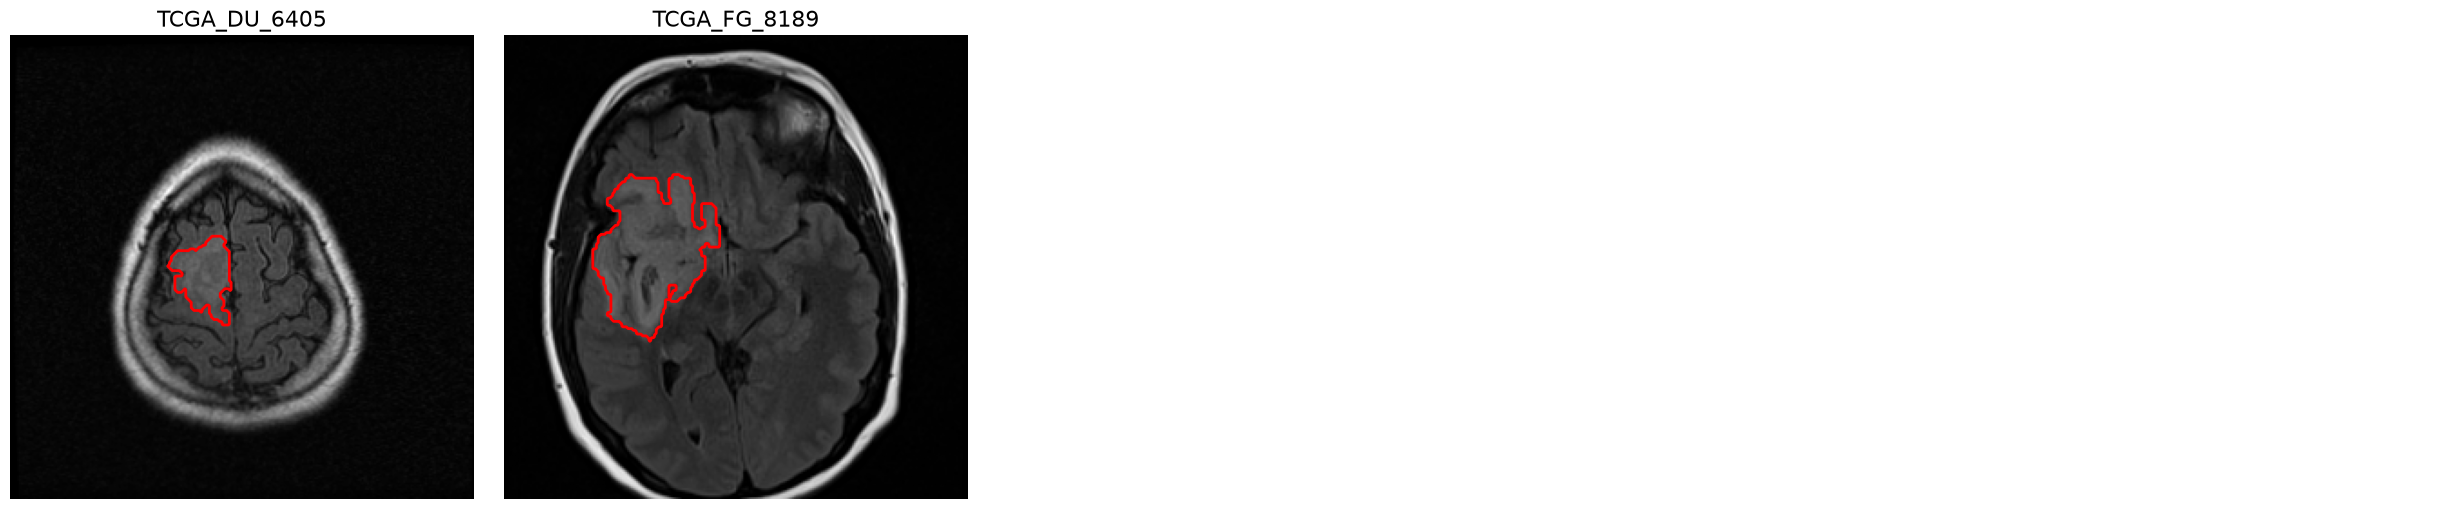

In [8]:
n = len(failed)
cols = 5
rows_needed = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_needed, cols, figsize=(5 * cols, 5.6 * rows_needed))
axes = np.array(axes).reshape(-1)

for ax, (_, patient_row) in zip(axes, failed.iterrows()):
    patient_slices = slices[slices["Patient"] == patient_row["Patient"]]
    best_size = -1
    for _, candidate in patient_slices.iterrows():
        image_path, mask_path, _ = local_paths(candidate)
        size = (np.array(Image.open(mask_path)) > 0).sum()
        if size > best_size:
            best_size = size
            best = candidate

    image_path, mask_path, _ = local_paths(best)
    image = np.array(Image.open(image_path))
    mask = np.array(Image.open(mask_path)) > 0

    ax.imshow(image[:, :, 1], cmap="gray")
    ax.contour(mask, colors="red", linewidths=2)
    ax.set_title(patient_row["Patient"], fontsize=16)
    ax.grid(False)
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("failed_patients.png", dpi=150)
plt.show()

### Compare all three scan types for one failed patient
This shows the pre-contrast, FLAIR, and post-contrast channels side by side for the first failed patient. If two of them look identical, a scan was missing and filled in with the FLAIR.

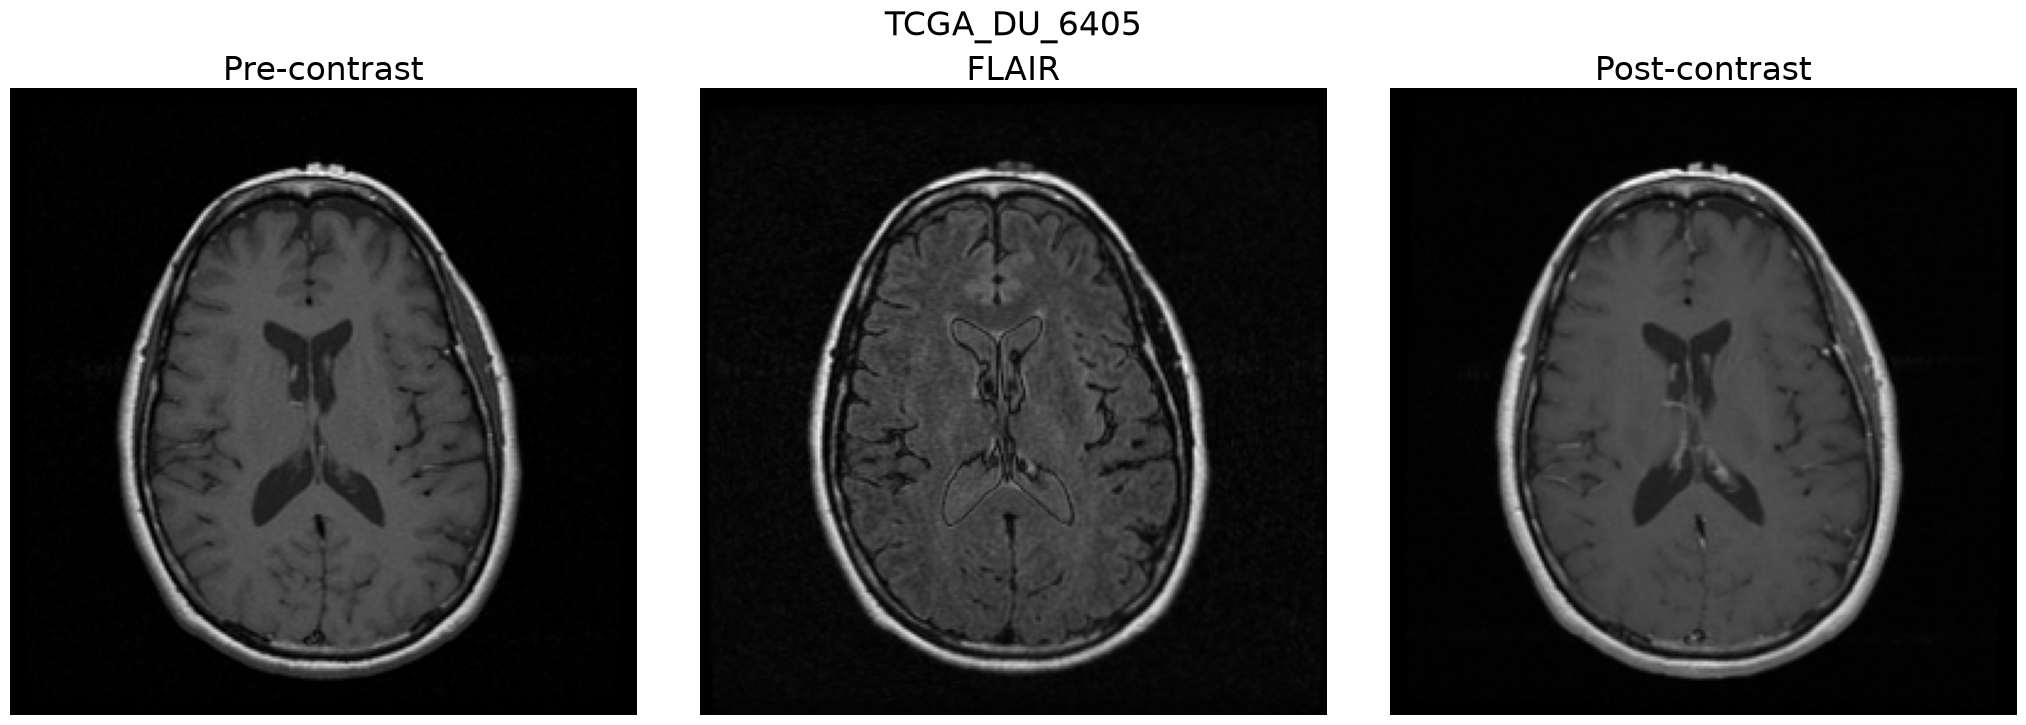

In [9]:
example = failed.iloc[0]
patient_slices = slices[slices["Patient"] == example["Patient"]]
middle = patient_slices.iloc[len(patient_slices) // 2]
image_path, _, _ = local_paths(middle)
image = np.array(Image.open(image_path))

fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))
for ax, channel, name in zip(axes, range(3), ["Pre-contrast", "FLAIR", "Post-contrast"]):
    ax.imshow(image[:, :, channel], cmap="gray")
    ax.set_title(name)
    ax.grid(False)
    ax.axis("off")
fig.suptitle(example["Patient"])
plt.tight_layout()
plt.show()